# Geometrie und Trigonometrie

## 07 - Trigonometrie 1: Rechtwinkliges Dreieck

Bisher hatten wir zwei getrenne Welten:
1. **Winkel** (gemessen in Grad, z.B. $30°$).
2. **Seitenlängen** (gemessen in Metern, cm, etc.).

Der Satz des Pythagoras ($a^2 + b^2 = c^2$) hilft uns nur, wenn wir zwei Seiten kennen und die dritte suchen. Er sagt uns nicht über die Winkel.
Was aber, wenn wir wissen wollen, wie hoch eine Rampe wird, wenn sie 10 Meter lang ist und einen Steigungswinkel von $15°$ hat?
Hier brauchen wir die **Trigonometrie**.

Mit der Trigonometrie bauen wir eine Brücke zwischen **Winekln** und **Längen**.

**Lernziele:**
- Du verstehst, warum Seitenverhältnisse in ähnlichen Dreiecken konstant sind.
- Du lernst die Definitionen von **Sinus**, **Cosinus** und **Tangens**.
- Du verstehst den Tangens als **Steigung**.
- Du kanns wichtige Werte (für $30°, 45°, 60°$) geometrisch herleiten, ohne Taschenrechner.
- Du kannst Python nutzen, um diese Zusammenhänge zu visalisieren.


### 1. Das Fundament: Ähnlichkeit

Warum funktionieren Sinus und Cosinus überhaupt?

Nehmen wir ein kleines rechtwinkliges Dreieck mit einem Winkel $\alpha = 30°$.
Dann nehmen wir ein riesiges rechtwinkliges Dreieck, das ebenfalls einen Winkel $\alpha = 30°$ hat.

Da beide Dreiecke zwei gleiche Winkel haben ($30°$ und $90°$), ist auch der dritte Winkel gleich ($60°$). Nach dem Ähnlichkeitssatz (WW) sind die Dreiecke **ähnlich**.

**Die Konsequenz:**
Das Verhältnis der Seitenlängen zueinander ist in beiden Dreiecken **identisch**.
Wenn im kleinen Dreieck die Höhe genau halb so lang ist wie die schräge Seite, dann ist das im riesigen Dreieck auch so.

Diese konstanten Verhältnisse haben Namen bekommen: Sinus, Cosinus und Tangens.

### 2. Die Definitionen

Um die Verhältnisse zu bilden, müssen wir die Seiten relativ zum betrachteten Winkel $\alpha$ benennen:

1.  **Hypotenuse ($H$):** Immer die längste Seite, gegenüber vom rechten Winkel.
2.  **Gegenkathete ($GK$):** Die Seite, die dem Winkel $\alpha$ **gegenüber** liegt.
3.  **Ankathete ($AK$):** Die Seite, die **am** Winkel $\alpha$ anliegt (und nicht die Hypotenuse ist).

Die drei Grundfunktionen sind definiert als:

$$\sin(\alpha) = \frac{\text{Gegenkathete}}{\text{Hypotenuse}} = \frac{GK}{H}$$

$$\cos(\alpha) = \frac{\text{Ankathete}}{\text{Hypotenuse}} = \frac{AK}{H}$$

$$\tan(\alpha) = \frac{\text{Gegenkathete}}{\text{Ankathete}} = \frac{GK}{AK}$$


In [9]:
# Settings für Intro Grafik

Trig_Intro_Grafik = {
    "angle_deg": 35,
    "hypotenuse": 10,
    "figsize": (8, 6),
    "color_gk": "red",
    "color_ak": "blue",
    "color_hyp": "black"
}

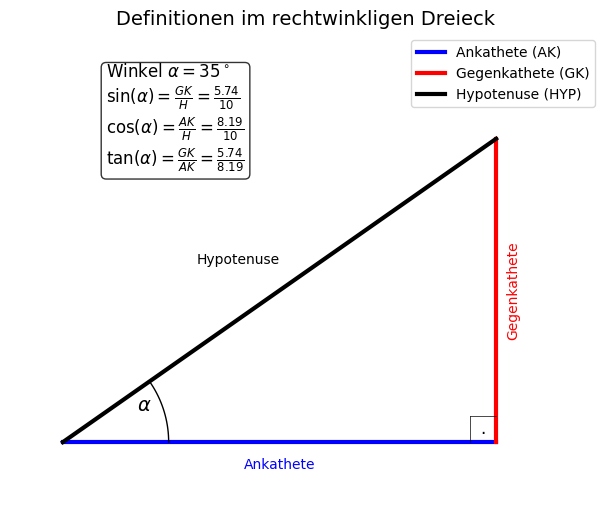

In [17]:
import numpy as np
import matplotlib.pyplot as plt

def plot_trig_definitions(ax, cfg):
    alpha = np.radians(cfg["angle_deg"])
    h = cfg["hypotenuse"]

    # Katheten berechnen
    ak = h * np.cos(alpha)
    gk = h * np.sin(alpha)

    # Dreieck zeichnen
    # Punkte: A(0,0), B(ak,0), C(ak,gk)
    ax.plot([0, ak], [0, 0], color=cfg["color_ak"], lw=3, label="Ankathete (AK)")
    ax.plot([ak, ak], [0, gk], color=cfg["color_gk"], lw=3, label="Gegenkathete (GK)")
    ax.plot([0, ak], [0, gk], color=cfg["color_hyp"], lw=3, label="Hypotenuse (HYP)")

    # Rechter Winkel
    box_s = h * 0.05
    ax.plot([ak, ak-box_s], [box_s, box_s], 'k-', lw=0.5)
    ax.plot([ak-box_s, ak-box_s], [0, box_s], 'k-', lw=0.5)
    ax.text(ak - box_s/2, box_s/2, ".", ha="center", va="center", fontsize=12)

    # Winkel Alpha Bogen
    arc_r = h * 0.2
    arc_x = np.linspace(0, alpha, 20)
    ax.plot(arc_r * np.cos(arc_x), arc_r * np.sin(arc_x), 'k-', lw=1)
    ax.text(arc_r * 0.7, arc_r * 0.3, r"$\alpha$", fontsize=14)

    """
    ValueError: 
Winkel $\alpha = 35^\circ$$\sin(\\alpha) = \\frac{GK}{H} = \\frac{5.74}{10} = {gk/h:.2f}$
                          ^
ParseException: Expected end of text, found '$'  (at char 26), (line:1, col:27)
    """

    # Formeln als Text
    info_text = (
        f"Winkel $\\alpha = {cfg['angle_deg']}^\\circ$\n"
        r"$\sin(\alpha) = \frac{GK}{H} = \frac{" + f"{gk:.2f}" + r"}{" + f"{h}" + r"}$" + "\n"
        r"$\cos(\alpha) = \frac{AK}{H} = \frac{" + f"{ak:.2f}" + r"}{" + f"{h}" + r"}$" + "\n"
        r"$\tan(\alpha) = \frac{GK}{AK} = \frac{" + f"{gk:.2f}" + r"}{" + f"{ak:.2f}" + r"}$"
    )
    ax.text(ak * 0.1, gk - 0.5, info_text, fontsize=12, bbox=dict(boxstyle="round", fc="white", alpha=0.8))

    # Labels an den Seiten
    ax.text(ak/2, -h*0.05, "Ankathete", ha='center', color=cfg["color_ak"])
    ax.text(ak + h*0.02, gk/2, "Gegenkathete", va='center', rotation=90, color=cfg["color_gk"])
    ax.text(ak/2, gk/2 + h*0.05, "Hypotenuse", ha='right', color=cfg["color_hyp"])

    ax.set_xlim(-1, ak +2)
    ax.set_ylim(-1, gk +2)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title("Definitionen im rechtwinkligen Dreieck", fontsize=14)
    ax.legend(loc='upper right')

fig, ax = plt.subplots(figsize=Trig_Intro_Grafik["figsize"])
plot_trig_definitions(ax, Trig_Intro_Grafik)
plt.show()



### 3. Der Tangens als Steigung

Erinnern wir uns an die lineare Funktionen: $y = k \cdot x + d$.

Dabei war $k$ die **Steigung** (oft auch $m$ genannt).

Die Steigung war definiert als: $\frac{\Delta y}{\Delta x}$ ("Höhenunterschied durch Längenunterschied").

Schauen wir uns das Dreieck oben an:
- $\Delta y$ ist die Gegenkathete.
- $\Delta x$ ist die Ankathete.

Daraus folgt eine der wichtigsten Erkenntnisse für die technische Mathematik:
**Die Steigung einer Geraden ist der Tangens ihres Steigungswinkels.**

$$\text{Steigung } k = \tan(\alpha)$$

Beispiel: Eine Straße mit $100\%$ Steigung.
Das heißt $\Delta y = \Delta x$ (z.B. 100m hoch auf 100m Distanz).
$\tan(\alpha) = 1$. Welcher Winkel hat den Tangens 1? $\rightarrow 45°$.
Eine 100%ige Steigung entspricht also einem $45°$-Winkel, nicht $90°$!